# Error model v3: systematic error per band + extra error along the refraction direction (positions after the exposure-CCD zero points, zeropoints.py)

Decided 2026-10-26 (Nada): refit sigma_sys on v2 positions and add a term along the parallactic (refraction)
direction that grows with airmass. Per epoch, in the frame of the parallactic direction p (towards the zenith) and the
perpendicular q:

    across (q):  sigma^2 = sigma_stat,q^2 + (s_b + m_b tan z)^2
    along  (p):  sigma^2 = sigma_stat,p^2 + (s_b + m_b tan z)^2 + (a_b + k_b tan z)^2

so the epoch's RA/Dec errors are correlated: C = C_stat + sigma_iso^2 I + (a_b + k_b tan z)^2 p p^T. (A first fit with
an airmass-independent s_b left the across pulls rising from ~0.85 to ~1.35 with tan z: most of the airmass dependence
is isotropic -- image motion from turbulence -- and only part of it is along the refraction direction.)
p = (-sin pa, -cos pa) in (RA*, Dec) (CCD x = -Dec, y = +RA; as brick_DCR). Data: per-epoch residuals of every clean
point source from its own straight-line fit (`py_files/pm_pulls.py`, v2, slices 000 and 040, 25% of bricks). A pull is
residual / sigma x sqrt(N / (N - 2)); a right error model gives unit robust width in every bin.

1. s_b, m_b: across pulls of unit width in every (tan z, mag) bin.  2. a_b, k_b: along pulls likewise. Writes `py_files/error_model_candidate.json`; adopted by moving it to `error_model.json` after review.

In [1]:
import os, sys, json, datetime
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
SLICES, FRACTION = ['000', '040'], 0.25
parts = [dict(np.load(f'{COMBINED_DIR}/pulls-{s}-{FRACTION}.npz')) for s in SLICES]
D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
sel = D['clean'] & np.isfinite(D['mag']) & (D['n'] >= 10) & np.isfinite(D['tanz'])
D = {k: v[sel] for k, v in D.items()}
BANDS = 'griz'
rs = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
dof = np.sqrt(D['n'] / (D['n'] - 2.))
s_, c_ = np.sin(D['pa']), np.cos(D['pa'])
r_p = -s_ * D['res_ra'] - c_ * D['res_dec']          # along the refraction direction (mas)
r_q = c_ * D['res_ra'] - s_ * D['res_dec']           # across
v_p = (s_ * D['sig_ra'])**2 + (c_ * D['sig_dec'])**2  # statistical variance along / across (mas^2)
v_q = (c_ * D['sig_ra'])**2 + (s_ * D['sig_dec'])**2
mb = np.arange(15, 26.01, 1.0); ib = np.digitize(D['mag'], mb) - 1
tb = np.array([0, 0.3, 0.5, 0.7, 0.9, 1.1, 1.4, 2.0]); it = np.digitize(D['tanz'], tb) - 1
print(f"{len(r_p):,} epochs of clean objects; tan z percentiles 5/50/95: {np.percentile(D['tanz'], [5, 50, 95]).round(2)}; "
      f"median |cos pa| {np.median(np.abs(c_)):.2f} (refraction mostly along Dec)")

/tmp/ipykernel_1858121/758286048.py:20: RuntimeWarning: overflow encountered in square
  v_q = (c_ * D['sig_ra'])**2 + (s_ * D['sig_dec'])**2


52,795,663 epochs of clean objects; tan z percentiles 5/50/95: [0.31 0.78 1.2 ]; median |cos pa| 0.65 (refraction mostly along Dec)


In [2]:
# 1. s_b from the across pulls (all magnitudes); 2. a_b, k_b from the along pulls in (tan z, mag) bins.
# Epochs are grouped by bin once; the (a, k) search runs on a coarse grid, then a fine one around the best point.
def groups(idx, keys):
    k = keys[idx]; o = np.argsort(k, kind='stable'); u, st = np.unique(k[o], return_index=True)
    return [g for g in np.split(idx[o], st[1:]) if len(g) >= 500]

def cost(r, var, grp):
    return sum(np.log(rs(r[g] / np.sqrt(var[g]) * dof[g]))**2 for g in grp)

FIT = {}
rng = np.random.default_rng(0)
for j, b in enumerate(BANDS):
    idx = np.flatnonzero(D['band'] == j); idx = np.sort(idx[rng.permutation(len(idx))[:3_000_000]])
    g_mag = groups(idx, ib); g_tm = groups(idx, it * 100 + ib)
    def search(fun, lo_a=0, lo_b=0):
        coarse = [(fun(x, y), x, y) for x in np.arange(0, 21, 2.) for y in np.arange(0, 21, 2.)]
        _, x0, y0 = min(coarse)
        fine = [(fun(x, y), x, y) for x in np.arange(max(x0 - 2, 0), x0 + 2.01, 0.5) for y in np.arange(max(y0 - 2, 0), y0 + 2.01, 0.5)]
        return min(fine)[1:]
    s0, s1 = search(lambda s0, s1: cost(r_q, v_q + (s0 + s1 * D['tanz'])**2, g_tm))
    iso2 = (s0 + s1 * D['tanz'])**2
    a1, k1 = search(lambda a, k: cost(r_p, v_p + iso2 + (a + k * D['tanz'])**2, g_tm))
    FIT[b] = {'sigma_sys': float(s0), 'sigma_sys_k': float(s1), 'along_a': float(a1), 'along_k': float(k1)}
    print(f"{b}: isotropic ({s0:.1f} + {s1:.1f} tan z) mas; extra along: ({a1:.1f} + {k1:.1f} tan z) mas  "
          f"[at tan z = 0.3 / 0.8 / 1.5: iso {s0 + 0.3 * s1:.1f} / {s0 + 0.8 * s1:.1f} / {s0 + 1.5 * s1:.1f}, "
          f"along {a1 + 0.3 * k1:.1f} / {a1 + 0.8 * k1:.1f} / {a1 + 1.5 * k1:.1f}]", flush=True)

g: isotropic (6.5 + 1.5 tan z) mas; extra along: (1.0 + 6.0 tan z) mas  [at tan z = 0.3 / 0.8 / 1.5: iso 7.0 / 7.7 / 8.8, along 2.8 / 5.8 / 10.0]


r: isotropic (5.5 + 2.0 tan z) mas; extra along: (0.0 + 6.5 tan z) mas  [at tan z = 0.3 / 0.8 / 1.5: iso 6.1 / 7.1 / 8.5, along 1.9 / 5.2 / 9.8]


i: isotropic (5.5 + 1.5 tan z) mas; extra along: (1.0 + 3.5 tan z) mas  [at tan z = 0.3 / 0.8 / 1.5: iso 6.0 / 6.7 / 7.8, along 2.0 / 3.8 / 6.2]


z: isotropic (5.5 + 2.0 tan z) mas; extra along: (0.0 + 5.0 tan z) mas  [at tan z = 0.3 / 0.8 / 1.5: iso 6.1 / 7.1 / 8.5, along 1.5 / 4.0 / 7.5]


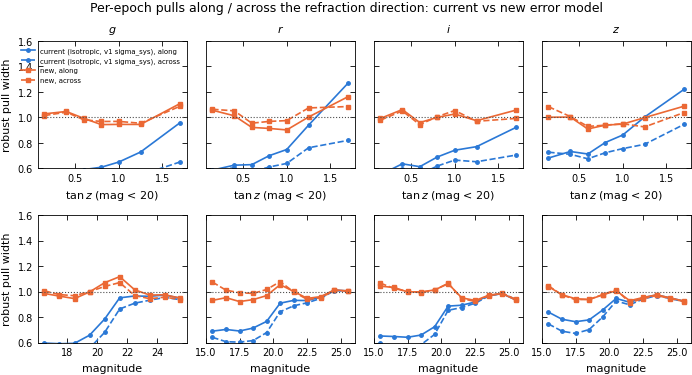

In [3]:
# Check: pull widths along / across vs tan z (bright, mag < 20) and vs magnitude, current vs new model
OLD = {'g': 16., 'r': 12., 'i': 12., 'z': 10.}
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 3.8), sharey=True, constrained_layout=True)
for j, b in enumerate(BANDS):
    m = D['band'] == j
    f = FIT[b]
    extra = (f['along_a'] + f['along_k'] * D['tanz'])**2
    iso2 = (f['sigma_sys'] + f['sigma_sys_k'] * D['tanz'])**2
    models = {'current (isotropic, v1 sigma_sys)': (v_p + OLD[b]**2, v_q + OLD[b]**2),
              'new': (v_p + iso2 + extra, v_q + iso2)}
    for k_, (name, (vp, vq)) in enumerate(models.items()):
        for comp, r, v, ls in (('along', r_p, vp, '-'), ('across', r_q, vq, '--')):
            p = r / np.sqrt(v) * dof
            tc = 0.5 * (tb[1:] + tb[:-1]); bright = m & (D['mag'] < 20)
            axes[0, j].plot(tc, [rs(p[bright & (it == q)]) if (bright & (it == q)).sum() > 2000 else np.nan for q in range(len(tc))],
                            ls=ls, marker=ps.MARKERS[k_], ms=2.5, color=ps.SERIES[k_], label=f'{name}, {comp}')
            mc = 0.5 * (mb[1:] + mb[:-1])
            axes[1, j].plot(mc, [rs(p[m & (ib == q)]) if (m & (ib == q)).sum() > 2000 else np.nan for q in range(len(mc))],
                            ls=ls, marker=ps.MARKERS[k_], ms=2.5, color=ps.SERIES[k_])
    for a in axes[:, j]: a.axhline(1, color='0.3', ls=':', lw=0.8)
    axes[0, j].set_title(f'${b}$'); axes[0, j].set_xlabel(r'$\tan z$ (mag < 20)'); axes[1, j].set_xlabel('magnitude')
axes[0, 0].set_ylabel('robust pull width'); axes[1, 0].set_ylabel('robust pull width'); axes[0, 0].set_ylim(0.6, 1.6)
axes[0, 0].legend(fontsize=5)
fig.suptitle('Per-epoch pulls along / across the refraction direction: current vs new error model')
plt.savefig('plots/error_model_fit.pdf')

In [4]:
# RA / Dec pull widths vs Dec with the new model (full 2x2 covariance projected on RA and Dec)
dec_edges = np.arange(-90, 46, 15)
for j, b in enumerate(BANDS):
    m = D['band'] == j; f = FIT[b]
    extra = (f['along_a'] + f['along_k'] * D['tanz'])**2
    iso2 = (f['sigma_sys'] + f['sigma_sys_k'] * D['tanz'])**2
    var_ra = D['sig_ra']**2 + iso2 + extra * s_**2
    var_de = D['sig_dec']**2 + iso2 + extra * c_**2
    pr, pd = D['res_ra'] / np.sqrt(var_ra) * dof, D['res_dec'] / np.sqrt(var_de) * dof
    print(f'{b}: RA/Dec pull width by Dec: ' + ', '.join(f'{lo}..{lo + 15}: {rs(pr[m & (D["dec"] >= lo) & (D["dec"] < lo + 15)]):.2f}/{rs(pd[m & (D["dec"] >= lo) & (D["dec"] < lo + 15)]):.2f}'
          for lo in dec_edges[:-1] if (m & (D['dec'] >= lo) & (D['dec'] < lo + 15)).sum() > 5000))

/tmp/ipykernel_1858121/2175766407.py:8: RuntimeWarning: overflow encountered in square
  var_de = D['sig_dec']**2 + iso2 + extra * c_**2


g: RA/Dec pull width by Dec: -90..-75: 0.97/0.98, -75..-60: 0.90/0.91, -60..-45: 0.95/0.96, -45..-30: 0.95/0.96, -30..-15: 0.93/0.94, -15..0: 0.95/0.96, 0..15: 0.96/0.97, 15..30: 1.01/1.03


r: RA/Dec pull width by Dec: -90..-75: 0.97/0.98, -75..-60: 0.96/0.97, -60..-45: 1.00/1.01, -45..-30: 0.99/1.01, -30..-15: 0.98/0.99, -15..0: 0.99/1.00, 0..15: 0.99/1.00, 15..30: 1.02/1.04


i: RA/Dec pull width by Dec: -90..-75: 0.95/0.98, -75..-60: 0.92/0.93, -60..-45: 0.96/0.97, -45..-30: 0.97/0.98, -30..-15: 0.98/0.98, -15..0: 0.97/0.98, 0..15: 0.97/0.98, 15..30: 1.06/1.11


z: RA/Dec pull width by Dec: -90..-75: 0.97/1.00, -75..-60: 0.92/0.93, -60..-45: 0.95/0.96, -45..-30: 0.96/0.97, -30..-15: 0.93/0.94, -15..0: 0.95/0.97, 0..15: 0.94/0.95, 15..30: 0.94/0.96


In [5]:
# Candidate parameters for py_files/error_model.json
model = {'description': 'Per-epoch error: across the parallactic direction sigma^2 = sigma_stat^2 + (sigma_sys + sigma_sys_k tan z)^2; '
                        'along it the same + (along_a + along_k tan z)^2 (mas). p = (-sin pa, -cos pa) in (RA*, Dec).',
         'bands': FIT, 'default_band': 'g',
         'fit': {'notebook': 'run/error-model-fit.ipynb', 'date': str(datetime.date.today()), 'slices': SLICES,
                 'fraction': FRACTION, 'n_epochs': int(len(r_p)), 'data': 'v2 per-epoch residuals of clean point sources'}}
json.dump(model, open('../py_files/error_model_candidate.json', 'w'), indent=1)
print(json.dumps(FIT, indent=1))

{
 "g": {
  "sigma_sys": 6.5,
  "sigma_sys_k": 1.5,
  "along_a": 1.0,
  "along_k": 6.0
 },
 "r": {
  "sigma_sys": 5.5,
  "sigma_sys_k": 2.0,
  "along_a": 0.0,
  "along_k": 6.5
 },
 "i": {
  "sigma_sys": 5.5,
  "sigma_sys_k": 1.5,
  "along_a": 1.0,
  "along_k": 3.5
 },
 "z": {
  "sigma_sys": 5.5,
  "sigma_sys_k": 2.0,
  "along_a": 0.0,
  "along_k": 5.0
 }
}
